<a href="https://colab.research.google.com/github/trishulip/YES-BANK-Stock-Price-Prediction/blob/main/notebooks/YES_BANK_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    TimeSeriesSplit
)

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

import warnings
warnings.filterwarnings('ignore')

print("All ML libraries imported successfully!")


All ML libraries imported successfully!


In [2]:

# Load original dataset
df = pd.read_csv("data_YesBank_StockPrices.csv")

# Convert date into datetime format
df['Date'] = pd.to_datetime(
    df['Date'], format='%b-%y'
)

# Sort data chronologically
df = df.sort_values('Date').reset_index(drop=True)

# Display dataset
display(df.head())

print("Dataset shape:", df.shape)


,Date,Open,High,Low,Close
0,2005-07-01,13.00,14.00,11.25,12.46
1,2005-08-01,12.58,14.88,12.55,13.42
2,2005-09-01,13.48,14.87,12.27,13.30
3,2005-10-01,13.20,14.47,12.40,12.99
4,2005-11-01,13.35,13.88,12.88,13.41


Dataset shape: (185, 5)


In [3]:

# Create lagged features

df['Open_Lag1'] = df['Open'].shift(1)
df['High_Lag1'] = df['High'].shift(1)
df['Low_Lag1'] = df['Low'].shift(1)
df['Close_Lag1'] = df['Close'].shift(1)

# Moving averages using only previous months
df['MA_3_Lag1'] = (
    df['Close'].shift(1).rolling(window=3).mean()
)

df['MA_6_Lag1'] = (
    df['Close'].shift(1).rolling(window=6).mean()
)

# Target: next month's closing price
df['Target'] = df['Close'].shift(-1)

# Remove rows with missing lagged values
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)

# Display prepared data
display(df.head(10))

print("Prepared dataset shape:", df.shape)


,Date,Open,High,Low,Close,Open_Lag1,High_Lag1,Low_Lag1,Close_Lag1,MA_3_Lag1,MA_6_Lag1,Target
0,2006-01-01,13.68,17.16,13.58,15.33,13.49,14.44,13.00,13.71,13.370000,13.215000,16.12
1,2006-02-01,15.50,16.97,15.40,16.12,13.68,17.16,13.58,15.33,14.150000,13.693333,20.08
2,2006-03-01,16.20,20.95,16.02,20.08,15.50,16.97,15.40,16.12,15.053333,14.143333,19.49
3,2006-04-01,20.56,20.80,18.02,19.49,16.20,20.95,16.02,20.08,17.176667,15.273333,18.03
4,2006-05-01,19.80,21.80,15.80,18.03,20.56,20.80,18.02,19.49,18.563333,16.356667,15.62
5,2006-06-01,18.20,18.40,13.40,15.62,19.80,21.80,15.80,18.03,19.200000,17.126667,16.16
6,2006-07-01,16.00,17.20,13.82,16.16,18.20,18.40,13.40,15.62,17.713333,17.445000,17.84
7,2006-08-01,15.90,18.60,15.70,17.84,16.00,17.20,13.82,16.16,16.603333,17.583333,18.46
8,2006-09-01,18.00,18.88,16.80,18.46,15.90,18.60,15.70,17.84,16.540000,17.870000,22.78
9,2006-10-01,18.78,24.20,18.50,22.78,18.00,18.88,16.80,18.46,17.486667,17.600000,25.32


Prepared dataset shape: (178, 12)


In [4]:

# Independent variables (Features)

X = df[
    [
        'Open_Lag1',
        'High_Lag1',
        'Low_Lag1',
        'Close_Lag1',
        'MA_3_Lag1',
        'MA_6_Lag1'
    ]
]

# Dependent variable (Target)

y = df['Target']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())


Features shape: (178, 6)
Target shape: (178,)


,Open_Lag1,High_Lag1,Low_Lag1,Close_Lag1,MA_3_Lag1,MA_6_Lag1
0,13.49,14.44,13.00,13.71,13.370000,13.215000
1,13.68,17.16,13.58,15.33,14.150000,13.693333
2,15.50,16.97,15.40,16.12,15.053333,14.143333
3,16.20,20.95,16.02,20.08,17.176667,15.273333
4,20.56,20.80,18.02,19.49,18.563333,16.356667


In [5]:

# Chronological 80-20 split

split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 142
Testing records: 36


In [6]:

# Create Linear Regression model

lr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

# Train the model
lr_model.fit(X_train, y_train)

# Make predictions
lr_predictions = lr_model.predict(X_test)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


In [7]:

# Create Random Forest model

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [8]:

# Function to evaluate model performance

def evaluate_model(y_true, predictions, model_name):

    mae = mean_absolute_error(y_true, predictions)
    mse = mean_squared_error(y_true, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, predictions)

    return {
        'Model': model_name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    }


# Evaluate both models

lr_results = evaluate_model(
    y_test, lr_predictions, "Linear Regression"
)

rf_results = evaluate_model(
    y_test, rf_predictions, "Random Forest"
)

# Create comparison table

results = pd.DataFrame([
    lr_results,
    rf_results
])

display(results)


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,43.506745,3900.671888,62.455359,0.759806
1,Random Forest,40.168181,3103.215639,55.706513,0.808911


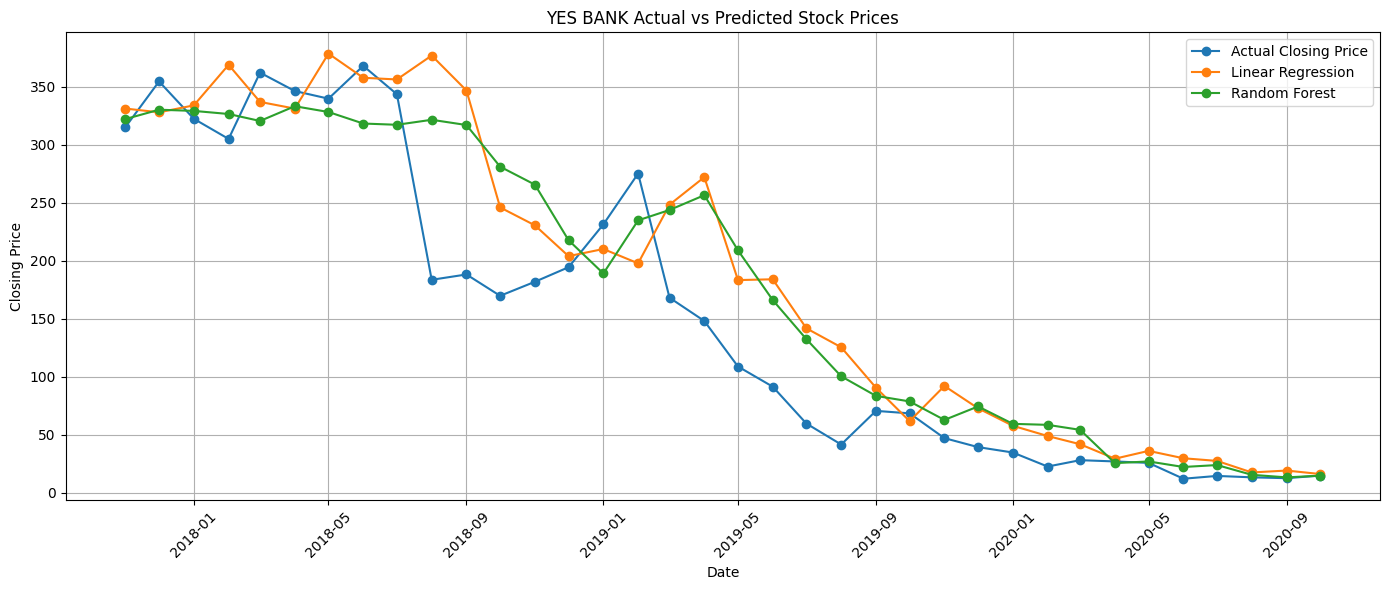

In [9]:

plt.figure(figsize=(14, 6))

plt.plot(
    df['Date'].iloc[split_index:],
    y_test,
    marker='o',
    label='Actual Closing Price'
)

plt.plot(
    df['Date'].iloc[split_index:],
    lr_predictions,
    marker='o',
    label='Linear Regression'
)

plt.plot(
    df['Date'].iloc[split_index:],
    rf_predictions,
    marker='o',
    label='Random Forest'
)

plt.title('YES BANK Actual vs Predicted Stock Prices')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [10]:

# Time series cross-validation

tscv = TimeSeriesSplit(n_splits=3)

# Hyperparameter grid

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

# Grid search

grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-validation MAE:")
print(-grid_search.best_score_)


Best Parameters:
{'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}

Best Cross-validation MAE:
43.04883167037702


In [11]:

# Get best model

best_rf_model = grid_search.best_estimator_

# Predict test data

tuned_predictions = best_rf_model.predict(X_test)

# Evaluate tuned model

tuned_results = evaluate_model(
    y_test,
    tuned_predictions,
    "Tuned Random Forest"
)

# Compare all three models

final_results = pd.DataFrame([
    lr_results,
    rf_results,
    tuned_results
])

display(final_results)


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,43.506745,3900.671888,62.455359,0.759806
1,Random Forest,40.168181,3103.215639,55.706513,0.808911
2,Tuned Random Forest,40.405129,3104.169257,55.715072,0.808853


,Feature,Importance
5,MA_6_Lag1,0.223183
3,Close_Lag1,0.221779
2,Low_Lag1,0.172500
1,High_Lag1,0.168151
4,MA_3_Lag1,0.164680
0,Open_Lag1,0.049707


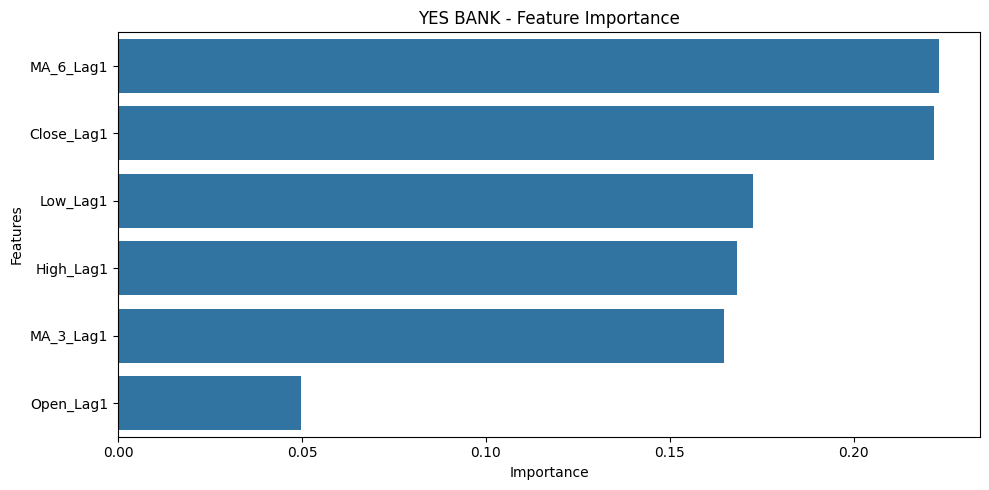

In [12]:

# Feature importance analysis

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance)

# Plot feature importance

plt.figure(figsize=(10, 5))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('YES BANK - Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()


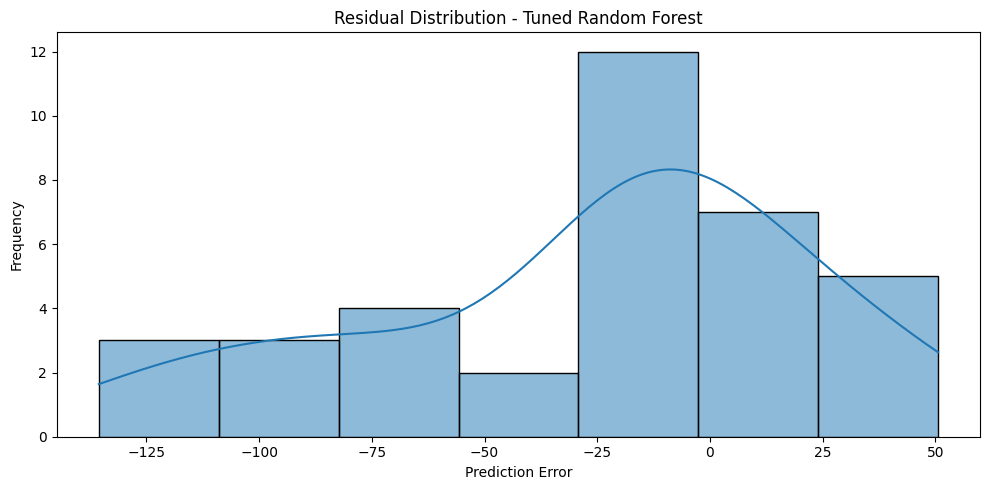

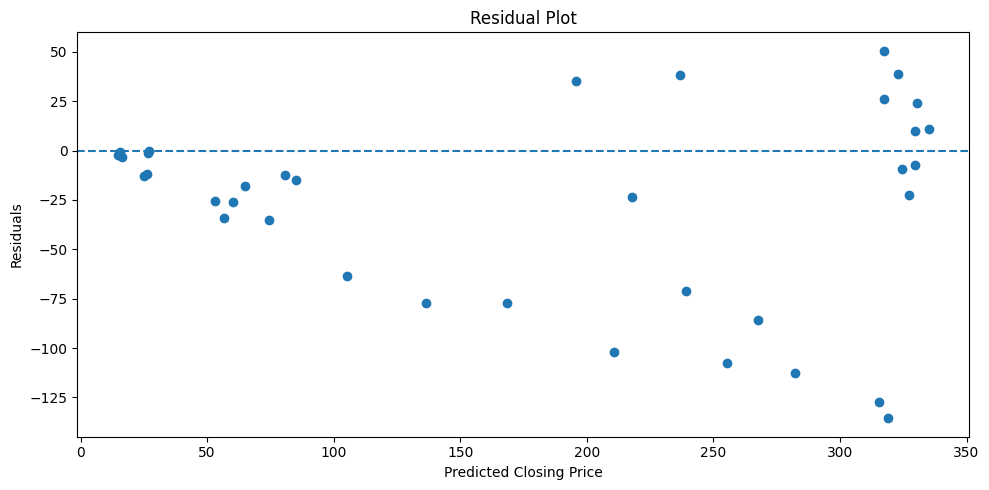

In [13]:

# Calculate residuals

residuals = y_test - tuned_predictions

# Residual distribution

plt.figure(figsize=(10, 5))

sns.histplot(residuals, kde=True)

plt.title('Residual Distribution - Tuned Random Forest')
plt.xlabel('Prediction Error')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

# Actual vs predicted residuals

plt.figure(figsize=(10, 5))

plt.scatter(tuned_predictions, residuals)
plt.axhline(y=0, linestyle='--')

plt.title('Residual Plot')
plt.xlabel('Predicted Closing Price')
plt.ylabel('Residuals')

plt.tight_layout()
plt.show()


In [14]:

# Display final model comparison

final_results = pd.DataFrame([
    lr_results,
    rf_results,
    tuned_results
])

display(final_results)

# Identify model with lowest RMSE

best_model_name = final_results.loc[
    final_results['RMSE'].idxmin(), 'Model'
]

print("Best model based on RMSE:", best_model_name)


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,43.506745,3900.671888,62.455359,0.759806
1,Random Forest,40.168181,3103.215639,55.706513,0.808911
2,Tuned Random Forest,40.405129,3104.169257,55.715072,0.808853


Best model based on RMSE: Random Forest


In [15]:

import joblib

# Save the tuned Random Forest model
joblib.dump(
    best_rf_model,
    'YES_BANK_Best_Model.pkl'
)

# Save model comparison
final_results.to_csv(
    'YES_BANK_Model_Comparison.csv',
    index=False
)

print("Model and evaluation results saved successfully!")


Model and evaluation results saved successfully!


Feature Importance:


,Feature,Importance
5,MA_6_Lag1,0.223183
3,Close_Lag1,0.221779
2,Low_Lag1,0.172500
1,High_Lag1,0.168151
4,MA_3_Lag1,0.164680
0,Open_Lag1,0.049707


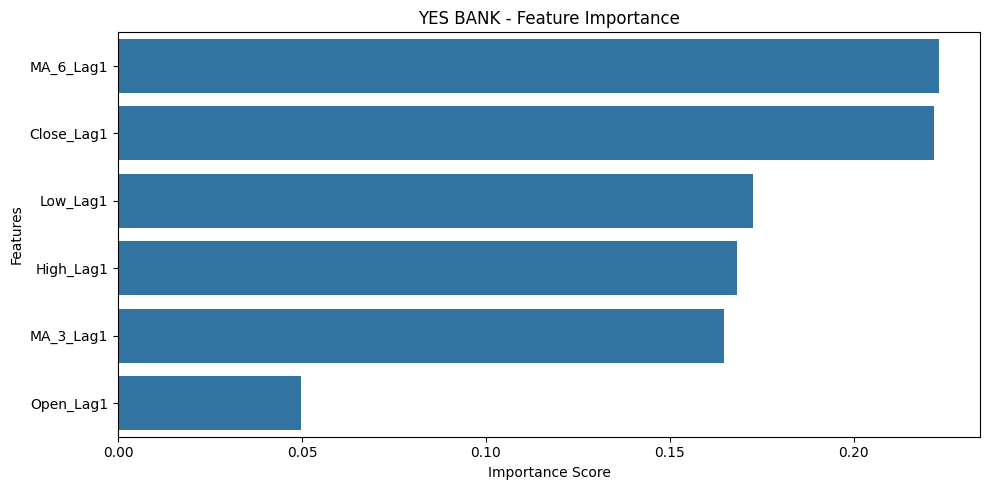

In [16]:

# Feature Importance Analysis

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Feature Importance:")
display(feature_importance)

# Visualize feature importance
plt.figure(figsize=(10, 5))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('YES BANK - Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()


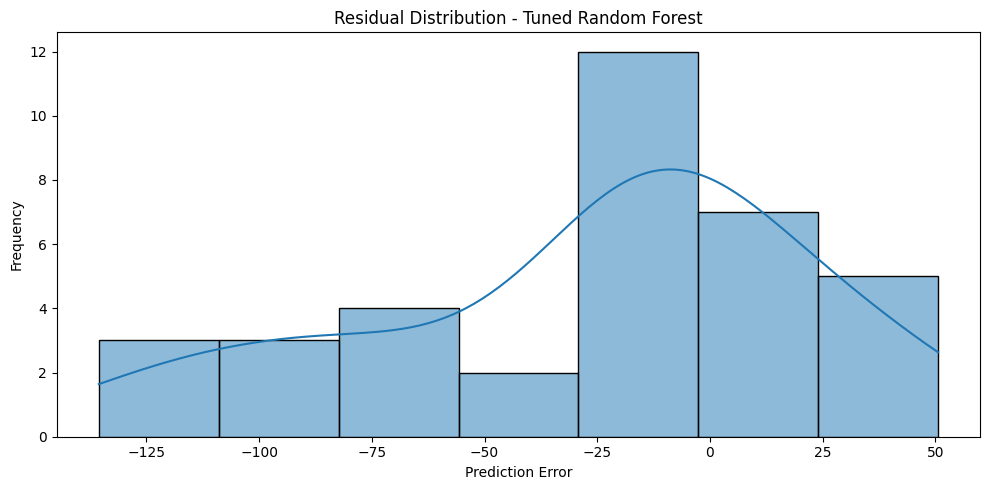

In [17]:

# Calculate prediction errors
residuals = y_test - tuned_predictions

# Plot residual distribution
plt.figure(figsize=(10, 5))

sns.histplot(residuals, kde=True)

plt.title('Residual Distribution - Tuned Random Forest')
plt.xlabel('Prediction Error')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


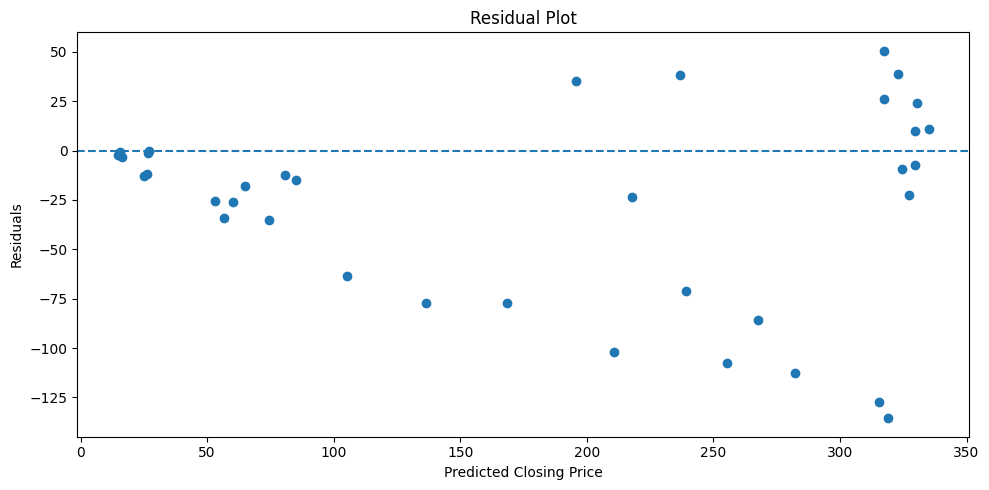

In [18]:

# Residual scatter plot

plt.figure(figsize=(10, 5))

plt.scatter(tuned_predictions, residuals)
plt.axhline(y=0, linestyle='--')

plt.title('Residual Plot')
plt.xlabel('Predicted Closing Price')
plt.ylabel('Residuals')

plt.tight_layout()
plt.show()


In [19]:

# Compare all trained models

final_results = pd.DataFrame([
    lr_results,
    rf_results,
    tuned_results
])

display(final_results)

# Identify model with lowest RMSE
best_model_name = final_results.loc[
    final_results['RMSE'].idxmin(), 'Model'
]

print("Best Model based on RMSE:", best_model_name)


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,43.506745,3900.671888,62.455359,0.759806
1,Random Forest,40.168181,3103.215639,55.706513,0.808911
2,Tuned Random Forest,40.405129,3104.169257,55.715072,0.808853


Best Model based on RMSE: Random Forest


In [20]:

import joblib

# Save tuned Random Forest model
joblib.dump(
    best_rf_model,
    'YES_BANK_Best_Model.pkl'
)

# Save comparison results
final_results.to_csv(
    'YES_BANK_Model_Comparison.csv',
    index=False
)

print("Model saved successfully!")


Model saved successfully!



# Conclusion

## YES BANK Stock Price Prediction

This project focuses on analysing historical YES BANK stock prices and developing machine learning models to predict future closing prices.

### Work Performed

- Exploratory Data Analysis
- Data Cleaning and Outlier Detection
- Feature Engineering
- Correlation Analysis
- Linear Regression
- Random Forest Regression
- Hyperparameter Tuning
- Model Evaluation and Explainability

### Model Evaluation

The models were evaluated using:
- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- R2 Score

The final model was selected based on its performance on unseen test data.

### Final Outcome

This project demonstrates the application of machine learning techniques to historical YES BANK stock price analysis.


## Final Model Performance and Conclusion

Three regression models were evaluated for YES BANK stock price prediction.

| Model | MAE | RMSE | R² Score |
|---|---:|---:|---:|
| Linear Regression | 43.51 | 62.46 | 0.7598 |
| Random Forest | 40.17 | 55.71 | 0.8089 |
| Tuned Random Forest | 40.41 | 55.72 | 0.8089 |

### Key Findings

- Random Forest achieved the lowest RMSE of 55.71.
- Random Forest achieved the highest R² score of approximately 0.8089.
- Linear Regression performed comparatively worse.
- Hyperparameter tuning did not produce a meaningful improvement over the original Random Forest model.

### Final Conclusion

Random Forest Regression was selected as the best-performing model based on the evaluation results. The model demonstrated better predictive performance than Linear Regression on the test dataset.

However, the residual analysis indicates that prediction errors remain, particularly during periods of significant stock-price fluctuations.

The project demonstrates the application of exploratory data analysis, feature engineering and machine learning techniques to historical YES BANK stock-price prediction.